In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path
import json

BASE_DIR = Path(Path.cwd())  # Notebook is inside notebooks/
DATA_DIR = BASE_DIR / "data"
CHART_DIR = BASE_DIR / "charts"

CHART_DIR.mkdir(exist_ok=True)

us_df = pd.read_csv(DATA_DIR / "USvideos.csv")
gb_df = pd.read_csv(DATA_DIR / "GBvideos.csv")
in_df = pd.read_csv(DATA_DIR / "INvideos.csv")

categories_df = pd.read_csv(DATA_DIR / "categories.csv")

us_df["country"] = "US"
gb_df["country"] = "GB"
in_df["country"] = "IN"

df = pd.concat(
    [us_df, gb_df, in_df],
    ignore_index=True
)

print("Dataset shape:", df.shape)
print("Countries:", df["country"].unique())

Dataset shape: (46230, 17)
Countries: <ArrowStringArray>
['US', 'GB', 'IN']
Length: 3, dtype: str


In [7]:
display(df.head())

print("Shape:", df.shape)

df.info()

display(df.describe(include="all").T)

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,g_N-w8LeAi8,17.14.11,Honest Football Prank LEAKED,QuietSpeech10,22,2017-11-14T07:04:28.000Z,Monsoon|Robots,48555,2189.0,180,136.0,https://i.ytimg.com/vi/g_N-w8LeAi8/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
1,Ugyql2NlPAd,17.14.11,Surprising Cricket Review,IncredibleChallenge41,25,2017-11-12T22:35:48.000Z,Winter,198385,1159.0,492,1446.0,https://i.ytimg.com/vi/Ugyql2NlPAd/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
2,8fE19jkxJ9n,17.14.11,Mira Solis - Football (Live) OFFICIAL,WildTutorial42,10,2017-11-13T08:40:22.000Z,Cricket,231656,8742.0,896,432.0,https://i.ytimg.com/vi/8fE19jkxJ9n/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
3,WOY0nn7HCsO,17.14.11,Zed Rivera - Space (Lyric Video)?!,ShockingInterview30,10,2017-10-27T22:21:47.000Z,Festival|Guitar,8083,176.0,8,19.0,https://i.ytimg.com/vi/WOY0nn7HCsO/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US
4,2Lc_Cs5VVr_,17.14.11,Surprising Election Recipe,UltimateVlog96,27,2017-11-09T13:20:20.000Z,Festival,373161,11305.0,167,891.0,https://i.ytimg.com/vi/2Lc_Cs5VVr_/default.jpg,False,False,False,Watch this video. Subscribe for more content a...,US


Shape: (46230, 17)
<class 'pandas.DataFrame'>
RangeIndex: 46230 entries, 0 to 46229
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   video_id                46230 non-null  str    
 1   trending_date           46230 non-null  str    
 2   title                   46230 non-null  str    
 3   channel_title           46230 non-null  str    
 4   category_id             46230 non-null  int64  
 5   publish_time            46230 non-null  str    
 6   tags                    46230 non-null  str    
 7   views                   46230 non-null  int64  
 8   likes                   46218 non-null  float64
 9   dislikes                46230 non-null  int64  
 10  comment_count           46194 non-null  float64
 11  thumbnail_link          46230 non-null  str    
 12  comments_disabled       46230 non-null  bool   
 13  ratings_disabled        46230 non-null  bool   
 14  video_error_or_removed  46230 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
video_id,46230,14699,iAvRHGeUpBR,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trending_date,46230,80,17.30.12,608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,46230,10404,Sunny Park - Bangalore (Live),66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_title,46230,438,QuietChallenge75,2464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_id,46230.0,NaN,NaN,NaN,18.645339,7.646745,1.0,10.0,22.0,24.0,28.0
publish_time,46230,14678,2017-11-27T11:50:56.000Z,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tags,46230,6056,[none],3785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
views,46230.0,NaN,NaN,NaN,1178603.180748,5916188.240094,1066.0,129463.25,318277.5,824050.5,360760164.0
likes,46218.0,NaN,NaN,NaN,45800.054849,296955.393069,0.0,3656.0,10201.0,28987.75,27537822.0
dislikes,46230.0,NaN,NaN,NaN,2325.983625,10518.962756,0.0,213.0,594.0,1666.0,618175.0


In [8]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

missing_report = missing_report[
    missing_report["missing_count"] > 0
].sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_report)

,missing_count,missing_percentage
description,1624,3.512870
comment_count,36,0.077872
likes,12,0.025957


In [9]:
df["trending_date"] = pd.to_datetime(
    df["trending_date"],
    errors="coerce"
)

df["publish_time"] = pd.to_datetime(
    df["publish_time"],
    errors="coerce",
    utc=True
)

numeric_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count",
    "category_id"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

boolean_columns = [
    "comments_disabled",
    "ratings_disabled",
    "video_error_or_removed"
]

for col in boolean_columns:
    df[col] = (
        df[col]
        .astype("boolean")
    )

C:\Users\Muthukumar Ramasamy\AppData\Local\Temp\ipykernel_25904\4230940728.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["trending_date"] = pd.to_datetime(


In [10]:
duplicate_count = df.duplicated(
    subset=["video_id", "trending_date", "country"]
).sum()

print("Duplicates:", duplicate_count)

df = df.drop_duplicates(
    subset=["video_id", "trending_date", "country"]
).copy()

invalid_count = (
    df["video_error_or_removed"]
    .fillna(False)
    .sum()
)

print("Removed/error video records:", invalid_count)

df = df[
    ~df["video_error_or_removed"].fillna(False)
].copy()

Duplicates: 20431
Removed/error video records: 56


In [11]:
display(categories_df.head())
print(categories_df.columns.tolist())

,category_id,category_name
0,1,Film & Animation
1,2,Autos & Vehicles
2,10,Music
3,15,Pets & Animals
4,17,Sports


['category_id', 'category_name']


In [13]:
if {"category_id", "category_name"}.issubset(categories_df.columns):
    category_lookup = categories_df[
        ["category_id", "category_name"]
    ].copy()
elif "items" in categories_df.columns:
    category_records = []

    for item in categories_df["items"].dropna():
        category_json = json.loads(item)

        category_records.append({
            "category_id": int(category_json["id"]),
            "category_name": category_json["snippet"]["title"]
        })

    category_lookup = pd.DataFrame(category_records)

else:
    raise ValueError(
        "Unknown categories.csv structure. Inspect its columns."
    )    

In [14]:
df["category_id"] = df["category_id"].astype("Int64")

category_lookup["category_id"] = (
    pd.to_numeric(
        category_lookup["category_id"],
        errors="coerce"
    ).astype("Int64")
)

df = df.merge(
    category_lookup,
    on="category_id",
    how="left",
    validate="many_to_one"
)

print("Final shape:", df.shape)

Final shape: (25743, 18)


In [15]:
essential_columns = [
    "video_id",
    "trending_date",
    "views",
    "likes",
    "dislikes",
    "comment_count"
]

df = df.dropna(
    subset=essential_columns
).copy()

# Ensure metrics are non-negative
for col in ["views", "likes", "dislikes", "comment_count"]:
    df = df[df[col] >= 0].copy()

print("Cleaned shape:", df.shape)

Cleaned shape: (14552, 18)


In [16]:
display(
    df.isna().sum()[
        df.isna().sum() > 0
    ]
)

description    546
dtype: int64

In [17]:
df.to_csv(
    DATA_DIR / "cleaned_trending_data.csv",
    index=False
)

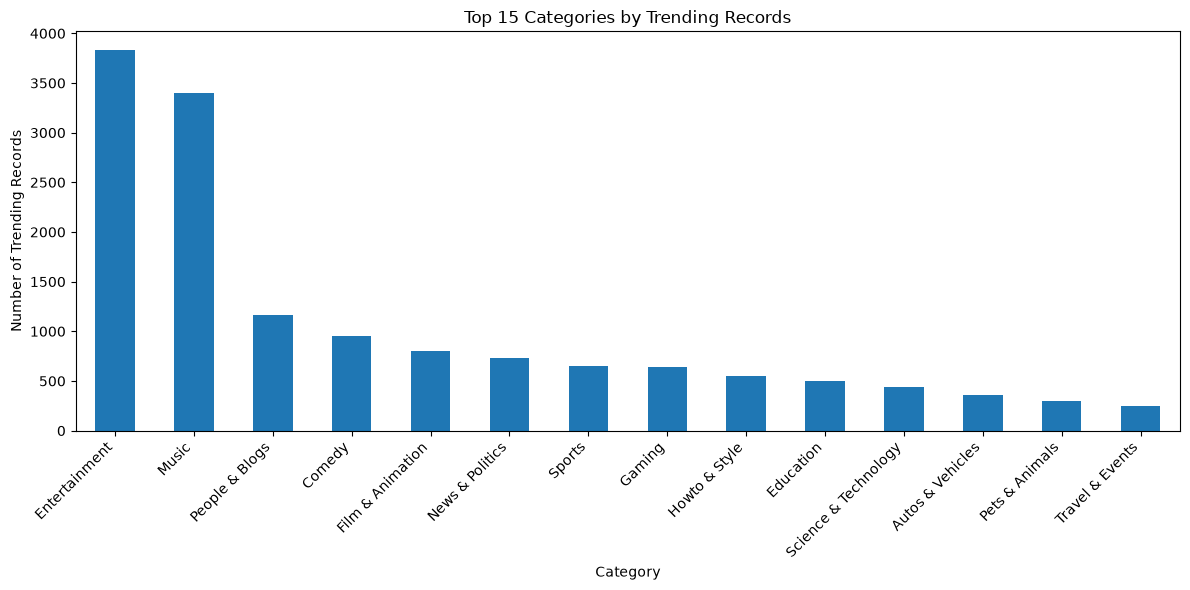

In [18]:
category_counts = (
    df["category_name"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))

category_counts.plot(
    kind="bar"
)

plt.title("Top 15 Categories by Trending Records")
plt.xlabel("Category")
plt.ylabel("Number of Trending Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(CHART_DIR / "category_counts.png")
plt.show()

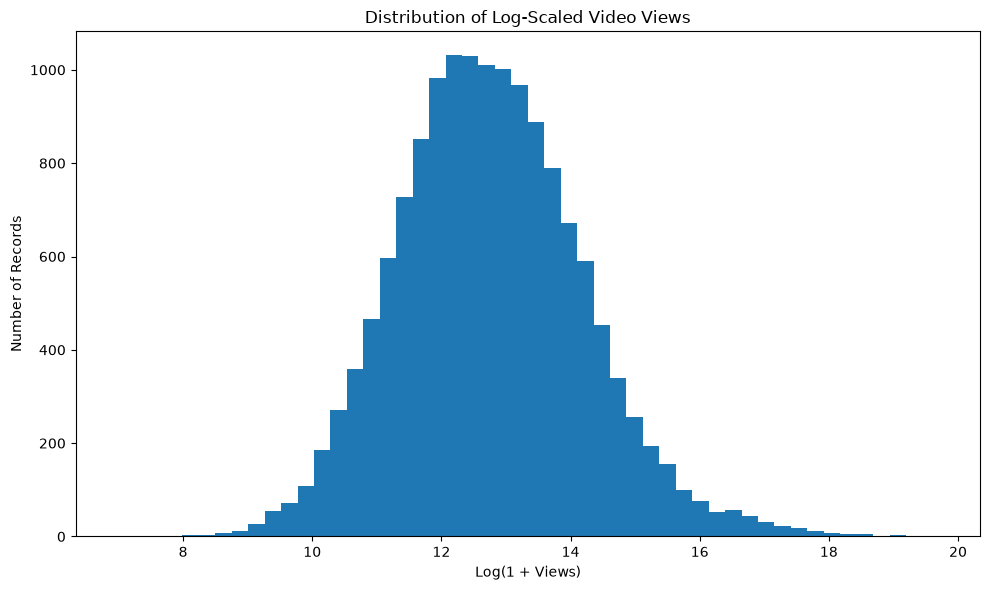

In [19]:
plt.figure(figsize=(10, 6))

plt.hist(
    np.log1p(df["views"]),
    bins=50
)

plt.title("Distribution of Log-Scaled Video Views")
plt.xlabel("Log(1 + Views)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig(CHART_DIR / "views_distribution.png")
plt.show()

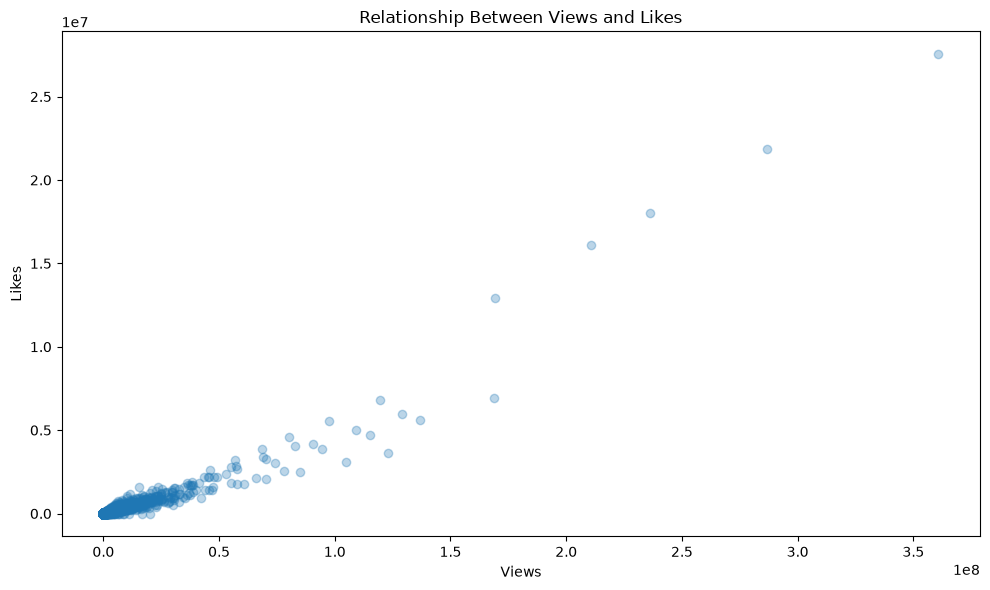

In [20]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["views"],
    df["likes"],
    alpha=0.3
)

plt.title("Relationship Between Views and Likes")
plt.xlabel("Views")
plt.ylabel("Likes")

plt.tight_layout()
plt.savefig(CHART_DIR / "views_vs_likes.png")
plt.show()

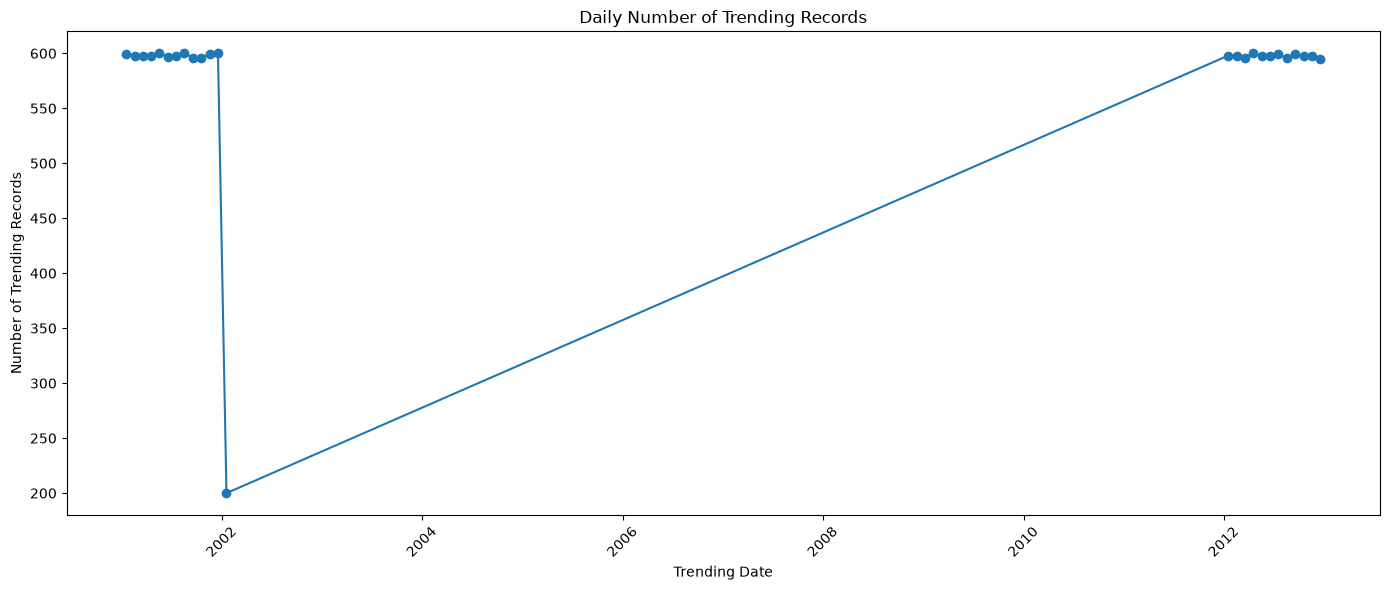

In [21]:
daily_trending = (
    df.groupby("trending_date")
    .size()
    .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    daily_trending.index,
    daily_trending.values,
    marker="o"
)

plt.title("Daily Number of Trending Records")
plt.xlabel("Trending Date")
plt.ylabel("Number of Trending Records")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(CHART_DIR / "daily_trending_records.png")
plt.show()

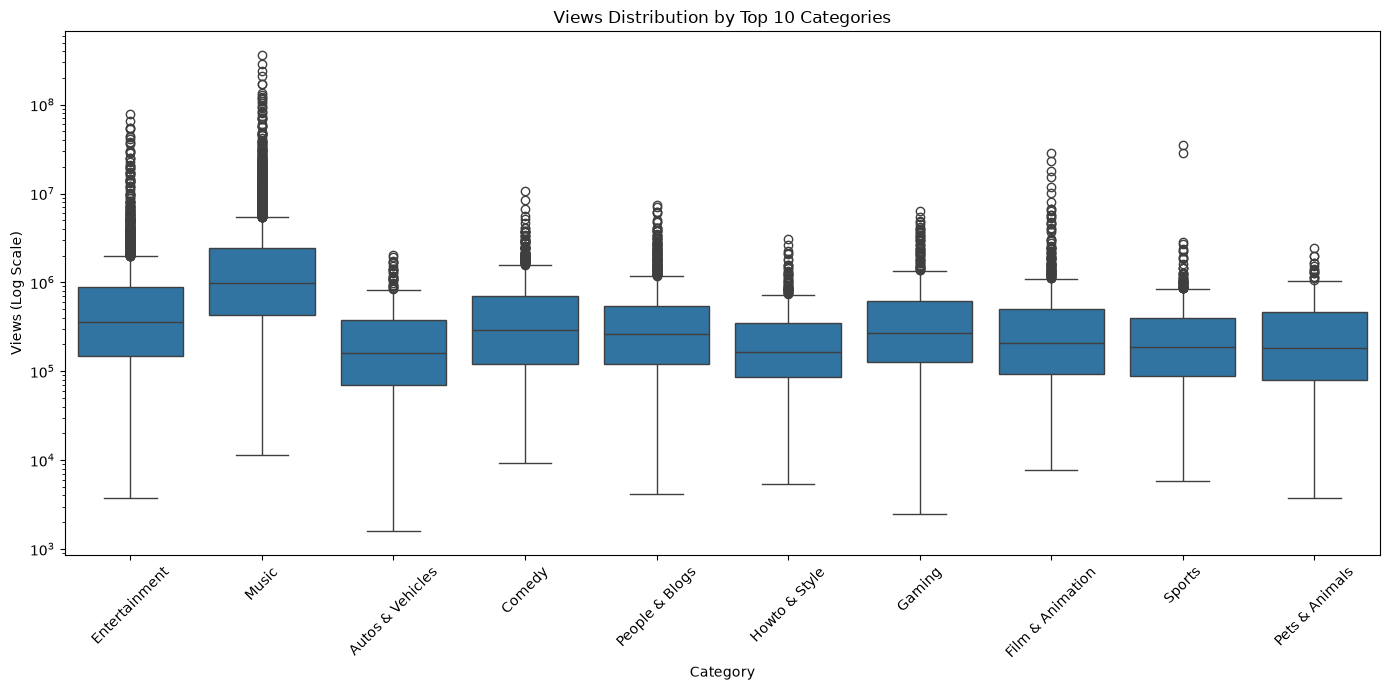

In [22]:
top_categories = (
    df.groupby("category_name")["views"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .index
)

box_data = df[
    df["category_name"].isin(top_categories)
].copy()

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=box_data,
    x="category_name",
    y="views"
)

plt.yscale("log")

plt.title("Views Distribution by Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Views (Log Scale)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(CHART_DIR / "views_by_category.png")
plt.show()

In [23]:
sample_df = df.sample(
    min(5000, len(df)),
    random_state=42
)

fig = px.scatter(
    sample_df,
    x="views",
    y="likes",
    color="category_name",
    hover_name="title",
    hover_data=[
        "country",
        "comment_count",
        "trending_date"
    ],
    title="Interactive Views vs Likes by Category",
    labels={
        "views": "Video Views",
        "likes": "Video Likes",
        "category_name": "Category"
    }
)

fig.show()

In [24]:
country_category_views = (
    df.groupby(
        ["country", "category_name"],
        as_index=False
    )["views"]
    .mean()
)

fig = px.bar(
    country_category_views,
    x="category_name",
    y="views",
    color="country",
    barmode="group",
    title="Average Views by Category Across Countries",
    labels={
        "category_name": "Category",
        "views": "Average Views",
        "country": "Country"
    }
)

fig.show()

In [25]:
def distribution_summary(series):
    return {
        "mean": series.mean(),
        "median": series.median(),
        "mode": series.mode().iloc[0],
        "skewness": series.skew()
    }

views_stats = distribution_summary(df["views"])
likes_stats = distribution_summary(df["likes"])

distribution_df = pd.DataFrame({
    "views": views_stats,
    "likes": likes_stats
})

display(distribution_df)

,views,likes
mean,1.324574e+06,54583.589885
median,3.255680e+05,10403.000000
mode,5.661400e+04,0.000000
skewness,2.549942e+01,40.432070


In [26]:
print("Views skewness:", df["views"].skew())
print("Likes skewness:", df["likes"].skew())

Views skewness: 25.499416136244097
Likes skewness: 40.43206954706006


In [27]:
def iqr_outlier_report(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (series < lower_bound) |
        (series > upper_bound)
    )

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percentage": outlier_mask.mean() * 100
    }

views_outliers = iqr_outlier_report(df["views"])
likes_outliers = iqr_outlier_report(df["likes"])

outlier_report = pd.DataFrame({
    "views": views_outliers,
    "likes": likes_outliers
})

display(outlier_report)

,views,likes
Q1,1.307810e+05,3692.750000
Q3,8.659142e+05,30847.250000
IQR,7.351332e+05,27154.500000
lower_bound,-9.719189e+05,-37039.000000
upper_bound,1.968614e+06,71579.000000
outlier_count,1.587000e+03,1632.000000
outlier_percentage,1.090572e+01,11.214953


In [28]:
df["publish_date"] = (
    df["publish_time"]
    .dt.tz_convert(None)
    .dt.normalize()
)

df["first_trending_date"] = (
    df.groupby(["video_id", "country"])["trending_date"]
    .transform("min")
)

df["days_to_trend"] = (
    df["first_trending_date"] -
    df["publish_date"]
).dt.days

In [29]:
print(
    "Negative days_to_trend:",
    (df["days_to_trend"] < 0).sum()
)

Negative days_to_trend: 14552


In [30]:
correlation_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count",
    "days_to_trend"
]

correlation_df = df[
    correlation_columns
].corr(method="pearson")

display(correlation_df)

,views,likes,dislikes,comment_count,days_to_trend
views,1.000000,0.949321,0.937028,0.905036,-0.006184
likes,0.949321,1.000000,0.889419,0.825155,-0.015242
dislikes,0.937028,0.889419,1.000000,0.905456,0.001133
comment_count,0.905036,0.825155,0.905456,1.000000,0.001816
days_to_trend,-0.006184,-0.015242,0.001133,0.001816,1.000000


In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_df,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Video Metrics")
plt.tight_layout()

plt.savefig(CHART_DIR / "correlation_heatmap.png")
plt.show()

In [31]:
upper_triangle = correlation_df.where(
    np.triu(
        np.ones(correlation_df.shape),
        k=1
    ).astype(bool)
)

strongest_pairs = (
    upper_triangle
    .stack()
    .abs()
    .sort_values(ascending=False)
    .head(2)
)

print("Two strongest correlation pairs:")
display(strongest_pairs)

Two strongest correlation pairs:


views  likes       0.949321
       dislikes    0.937028
dtype: float64

In [32]:
video_summary = (
    df.groupby(
        ["video_id", "country"],
        as_index=False
    )
    .agg(
        title=("title", "first"),
        category_name=("category_name", "first"),
        peak_views=("views", "max"),
        peak_likes=("likes", "max"),
        peak_comments=("comment_count", "max"),
        first_trending_date=("trending_date", "min"),
        last_trending_date=("trending_date", "max"),
        trending_days=("trending_date", "nunique")
    )
)

print("Unique videos:", len(video_summary))

Unique videos: 5570


In [33]:
median_peak_views = video_summary["peak_views"].median()

p90_peak_views = video_summary["peak_views"].quantile(0.90)

In [34]:
stage1 = video_summary

stage2 = video_summary[
    video_summary["peak_views"] > median_peak_views
]

stage3 = stage2[
    stage2["peak_views"] > p90_peak_views
]

stage4 = stage3[
    stage3["peak_comments"] >= 1000
]

In [35]:
stage_data = [
    ("All videos that trended", len(stage1)),
    ("Above median peak views", len(stage2)),
    ("Above 90th percentile peak views", len(stage3)),
    ("1,000+ peak comments", len(stage4))
]

funnel_df = pd.DataFrame(
    stage_data,
    columns=["stage", "video_count"]
)

funnel_df["conversion_rate"] = (
    funnel_df["video_count"] /
    funnel_df["video_count"].iloc[0] * 100
)

funnel_df["stage_to_stage_conversion"] = (
    funnel_df["video_count"] /
    funnel_df["video_count"].shift(1) * 100
)

funnel_df["drop_off_count"] = (
    funnel_df["video_count"].shift(1) -
    funnel_df["video_count"]
)

display(funnel_df)

,stage,video_count,conversion_rate,stage_to_stage_conversion,drop_off_count
0,All videos that trended,5570,100.00000,NaN,NaN
1,Above median peak views,2785,50.00000,50.000000,2785.0
2,Above 90th percentile peak views,557,10.00000,20.000000,2228.0
3,"1,000+ peak comments",548,9.83842,98.384201,9.0


In [36]:
drop_offs = funnel_df["drop_off_count"].iloc[1:]

largest_drop_stage = drop_offs.idxmax()

print(
    "Largest drop-off stage:",
    funnel_df.loc[largest_drop_stage, "stage"]
)

print(
    "Videos lost:",
    funnel_df.loc[largest_drop_stage, "drop_off_count"]
)

Largest drop-off stage: Above median peak views
Videos lost: 2785.0


In [37]:
retention_data = (
    df.groupby(
        ["video_id", "country"],
        as_index=False
    )
    .agg(
        category_name=("category_name", "first"),
        first_trending_date=("trending_date", "min"),
        trending_days=("trending_date", "nunique")
    )
)

print(retention_data.head())

      video_id country  category_name first_trending_date  trending_days
0  --pb5oKkYrH      GB          Music          2012-04-17              4
1  -0dHuLKRPYS      US         Sports          2002-01-18              1
2  -1B196P9MCk      US  Entertainment          2012-04-17              1
3  -3WfJZgVB5h      GB          Music          2001-01-18              2
4  -48JdRO2P5_      GB  Howto & Style          2012-06-17              2


In [38]:
retention_days = [1, 2, 3, 5, 7]

total_videos = len(retention_data)

retention_results = []

for day in retention_days:
    retained = (
        retention_data["trending_days"] >= day
    ).sum()

    percentage = (
        retained / total_videos * 100
        if total_videos else np.nan
    )

    retention_results.append({
        "day": day,
        "retained_videos": retained,
        "retention_percentage": percentage
    })

retention_df = pd.DataFrame(retention_results)

display(retention_df)

,day,retained_videos,retention_percentage
0,1,5570,100.000000
1,2,3284,58.958707
2,3,2064,37.055655
3,5,830,14.901257
4,7,347,6.229803


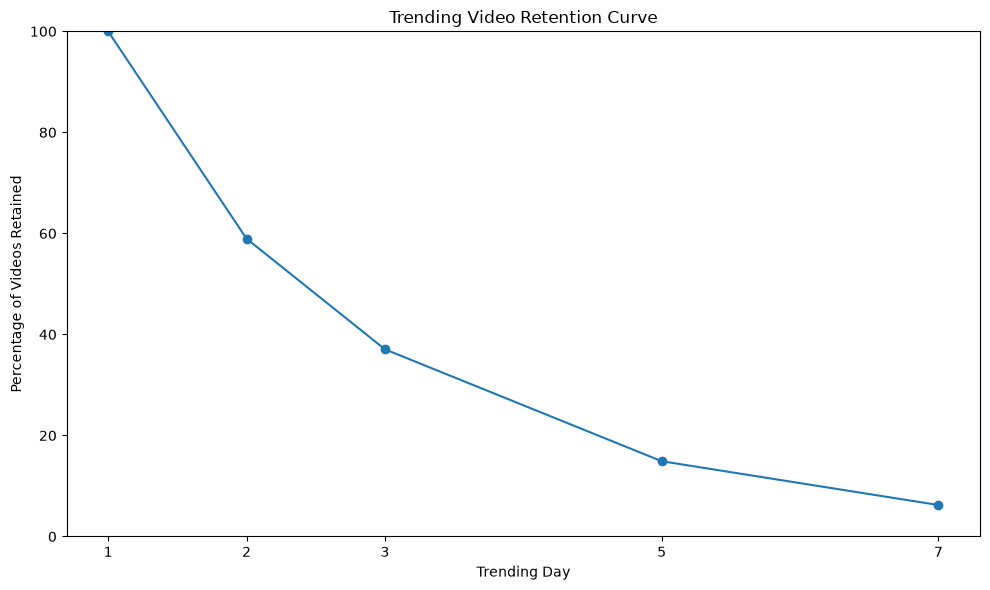

In [39]:
plt.figure(figsize=(10, 6))

plt.plot(
    retention_df["day"],
    retention_df["retention_percentage"],
    marker="o"
)

plt.title("Trending Video Retention Curve")
plt.xlabel("Trending Day")
plt.ylabel("Percentage of Videos Retained")
plt.xticks(retention_days)
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig(CHART_DIR / "retention_curve.png")
plt.show()

In [40]:
category_video_counts = (
    retention_data["category_name"]
    .value_counts()
)

selected_categories = (
    category_video_counts[
        category_video_counts >= 30
    ]
    .head(5)
    .index
)

category_retention = []

for category in selected_categories:
    category_df = retention_data[
        retention_data["category_name"] == category
    ]

    total = len(category_df)

    for day in retention_days:
        retained = (
            category_df["trending_days"] >= day
        ).sum()

        category_retention.append({
            "category_name": category,
            "day": day,
            "retention_percentage": retained / total * 100
        })

category_retention_df = pd.DataFrame(
    category_retention
)

fig = px.line(
    category_retention_df,
    x="day",
    y="retention_percentage",
    color="category_name",
    markers=True,
    title="Trending Retention by Category",
    labels={
        "day": "Trending Day",
        "retention_percentage": "Retention (%)",
        "category_name": "Category"
    }
)

fig.show()

In [41]:
country_retention = []

for country in retention_data["country"].unique():
    country_df = retention_data[
        retention_data["country"] == country
    ]

    total = len(country_df)

    for day in retention_days:
        retained = (
            country_df["trending_days"] >= day
        ).sum()

        country_retention.append({
            "country": country,
            "day": day,
            "retention_percentage": retained / total * 100
        })

country_retention_df = pd.DataFrame(
    country_retention
)

fig = px.line(
    country_retention_df,
    x="day",
    y="retention_percentage",
    color="country",
    markers=True,
    title="Trending Retention by Country",
    labels={
        "day": "Trending Day",
        "retention_percentage": "Retention (%)",
        "country": "Country"
    }
)

fig.show()

In [42]:
cohort_df = retention_data.copy()

cohort_df["cohort_week"] = (
    cohort_df["first_trending_date"]
    .dt.to_period("W")
    .astype(str)
)

In [43]:
cohort_summary = (
    cohort_df.groupby("cohort_week")
    .agg(
        video_count=("video_id", "count"),
        average_lifespan=("trending_days", "mean"),
        median_lifespan=("trending_days", "median")
    )
    .reset_index()
)

display(cohort_summary)

,cohort_week,video_count,average_lifespan,median_lifespan
0,2001-01-15/2001-01-21,599,3.450751,3.0
1,2001-02-12/2001-02-18,182,3.296703,2.0
2,2001-03-12/2001-03-18,181,2.939227,2.0
3,2001-04-16/2001-04-22,188,2.744681,2.0
4,2001-05-14/2001-05-20,193,2.829016,2.0
5,2001-06-18/2001-06-24,200,2.655000,2.0
6,2001-07-16/2001-07-22,214,2.598131,2.0
7,2001-08-13/2001-08-19,207,2.454106,2.0
8,2001-09-17/2001-09-23,179,2.458101,2.0
9,2001-10-15/2001-10-21,186,2.102151,2.0


In [44]:
fig = px.bar(
    cohort_summary,
    x="cohort_week",
    y="average_lifespan",
    hover_data=[
        "video_count",
        "median_lifespan"
    ],
    title="Average Trending Lifespan by Weekly Cohort",
    labels={
        "cohort_week": "First Trending Week",
        "average_lifespan": "Average Trending Days"
    }
)

fig.show()

In [45]:
retention_data = (
    df.groupby(
        ["video_id", "country"],
        as_index=False
    )
    .agg(
        category_name=("category_name", "first"),
        first_trending_date=("trending_date", "min"),
        trending_days=("trending_date", "nunique")
    )
)